## Transition Matrix for DeepVelo

#### By: Josh Navarro

### SET UP

In [1]:
# Import that we will be using.
import pandas as pd
import numpy as np
import scvelo as scv
import torch
from umap import UMAP
from sklearn.decomposition import PCA
from scipy.stats import mannwhitneyu
import anndata as ann
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse

from deepvelo.utils import (
    velocity,
    velocity_confidence,
    continuity_confidence,
    update_dict,
    cross_boundary_correctness,
)
from deepvelo.utils.scatter import scatter
from deepvelo.utils.preprocess import autoset_coeff_s
from deepvelo.utils.plot import statplot, compare_plot
from deepvelo import train, Constants

Using backend: pytorch
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\scatter.py:5: DeprecationWarning: deepvelo.utils.scatter is deprecated. Please use deepvelo.plot.scatter instead.
  warnings.warn(
c:\Users\joshu\miniconda3\envs\deepvelo_env\lib\site-packages\deepvelo\utils\plot.py:5: DeprecationWarning: deepvelo.utils.plot is deprecated. Please use deepvelo.plot.plot instead.
  warnings.warn(


In [2]:
# use this fixed seed for the reproducibility
SEED = 123
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
np.random.seed(SEED)

scv.settings.verbosity = 3  # show errors(0), warnings(1), info(2), hints(3)
scv.settings.set_figure_params(
    "scvelo", transparent=False
)

In [3]:
adata = ann.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\DeepVelo\Figure_2_Follow\human_cd34_bone_marrow.h5ad")
scv.pp.filter_and_normalize(adata, min_shared_counts=20, n_top_genes=2000) # Filters and nomalizes the data
scv.pp.moments(adata, n_neighbors=30, n_pcs=30) # Look like its some modeling?

Filtered out 7837 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors
    finished (0:00:03) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


In [ ]:
scv.tl.velocity_graph(adata, n_jobs = 4)


computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/5780 [00:00<?, ?cells/s]

    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [7]:
adata.uns["neighbors"]["distances"] = adata.obsp["distances"]
adata.uns["neighbors"]["connectivities"] = adata.obsp["connectivities"]
scv.tl.paga(adata, groups="Celltype")
scv.pl.paga(
    adata,
    basis="tsne",
    size=30,
    alpha=0.1,
    min_edge_width=2,
    node_size_scale=1,
    dpi=150,
)

computing terminal states
    identified 6 regions of root cells and 3 regions of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
running PAGA using priors: ['velocity_pseudotime']


AssertionError: 

### LOOKING AT REBECCAS METHOD

In [9]:
# Adding latent time
scv.tl.recover_dynamics(adata)
scv.tl.latent_time(adata)

recovering dynamics (using 1/8 cores)


  0%|          | 0/479 [00:00<?, ?gene/s]

    finished (0:10:04) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing terminal states
    identified 6 regions of root cells and 3 regions of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior
    finished (0:00:01) --> added 
    'latent_time', shared time (adata.obs)


In [15]:
# Add the average latent time
connectivities = adata.obsp["connectivities"]
latent_time = adata.obs["latent_time"].to_numpy()

# Weighted average latent time among each cell's neighbors
neighbor_sum = np.asarray(connectivities.sum(axis=1)).ravel()

adata.obs["avg_latent_time"] = (
    np.asarray(connectivities @ latent_time).ravel()
    / neighbor_sum
)

In [16]:
scv.tl.velocity_graph(adata, vkey="velocity", sqrt_transform=True, approx=True, n_recurse_neighbors=1)

t_mat = scv.utils.get_transition_matrix(adata, vkey="velocity", self_transitions=False, backward=True)

computing velocity graph (using 1/8 cores)


  0%|          | 0/5780 [00:00<?, ?cells/s]

    finished (0:00:02) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [24]:
# current_cell_idx = 1

#########################

'''
prob_threshold = 0.01

adata.obs['transition_prob'] = np.nan
adata.obs.loc[adata.obs.index[current_cell_idx], 'transition_prob'] = 1 # mark origin cell

top_prob = 1
cell_idx_sequence = []
while (top_prob > prob_threshold):
    current_cell_time = adata.obs['avg_latent_time'][current_cell_idx]

    transition_probs = t_mat[current_cell_idx, :].toarray().flatten()
    prev_candidates = np.argsort(transition_probs)[::-1]
    prev_cell_idx = prev_candidates[0]
    top_prob = transition_probs[prev_cell_idx]

    i = 1
    while (prev_cell_idx in cell_idx_sequence):
        prev_cell_idx = prev_candidates[i]
        if transition_probs[prev_cell_idx] < prob_threshold:
            break
        i += 1

    print(f"cell {current_cell_idx} -> cell {prev_cell_idx} with prob {top_prob}")

    top_prob = transition_probs[prev_cell_idx]
    cell_idx_sequence.append(prev_cell_idx)

    adata.obs.loc[adata.obs.index[prev_cell_idx], 'transition_prob'] = top_prob

    current_cell_idx = cell_idx_sequence[-1]
    '''
current_cell_idx = 10
prob_threshold = 0.01

adata.obs["transition_prob"] = np.nan

# Mark the origin cell
adata.obs.loc[
    adata.obs.index[current_cell_idx],
    "transition_prob"
] = 1.0

# Include the starting cell in the path
cell_idx_sequence = [current_cell_idx]
transition_sequence = []

while True:

    current_cell_time = adata.obs["avg_latent_time"].iloc[current_cell_idx]

    transition_probs = (
        t_mat[current_cell_idx, :]
        .toarray()
        .flatten()
    )

    # Sort possible destination cells from highest to lowest probability
    candidates = np.argsort(transition_probs)[::-1]

    next_cell_idx = None
    next_probability = None

    for candidate_idx in candidates:

        candidate_probability = transition_probs[candidate_idx]

        # Stop searching if probabilities are already below the threshold
        if candidate_probability < prob_threshold:
            break

        # Skip cells already visited
        if candidate_idx in cell_idx_sequence:
            continue

        # Optional: only move forward in average latent time
        candidate_time = adata.obs["avg_latent_time"].iloc[candidate_idx]

        if candidate_time < current_cell_time:
            continue

        next_cell_idx = candidate_idx
        next_probability = candidate_probability
        break

    # No valid next cell was found
    if next_cell_idx is None:
        print(f"Path stopped at cell {current_cell_idx}")
        break

    print(
        f"cell {current_cell_idx} -> "
        f"cell {next_cell_idx} "
        f"with prob {next_probability}"
    )

    transition_sequence.append(next_probability)
    cell_idx_sequence.append(next_cell_idx)

    adata.obs.loc[
        adata.obs.index[next_cell_idx],
        "transition_prob"
    ] = next_probability

    current_cell_idx = next_cell_idx

cell 10 -> cell 5021 with prob 0.6009629368782043
cell 5021 -> cell 4913 with prob 0.5410627126693726
cell 4913 -> cell 3115 with prob 0.06845913082361221
cell 3115 -> cell 3770 with prob 0.7703133225440979
Path stopped at cell 3770


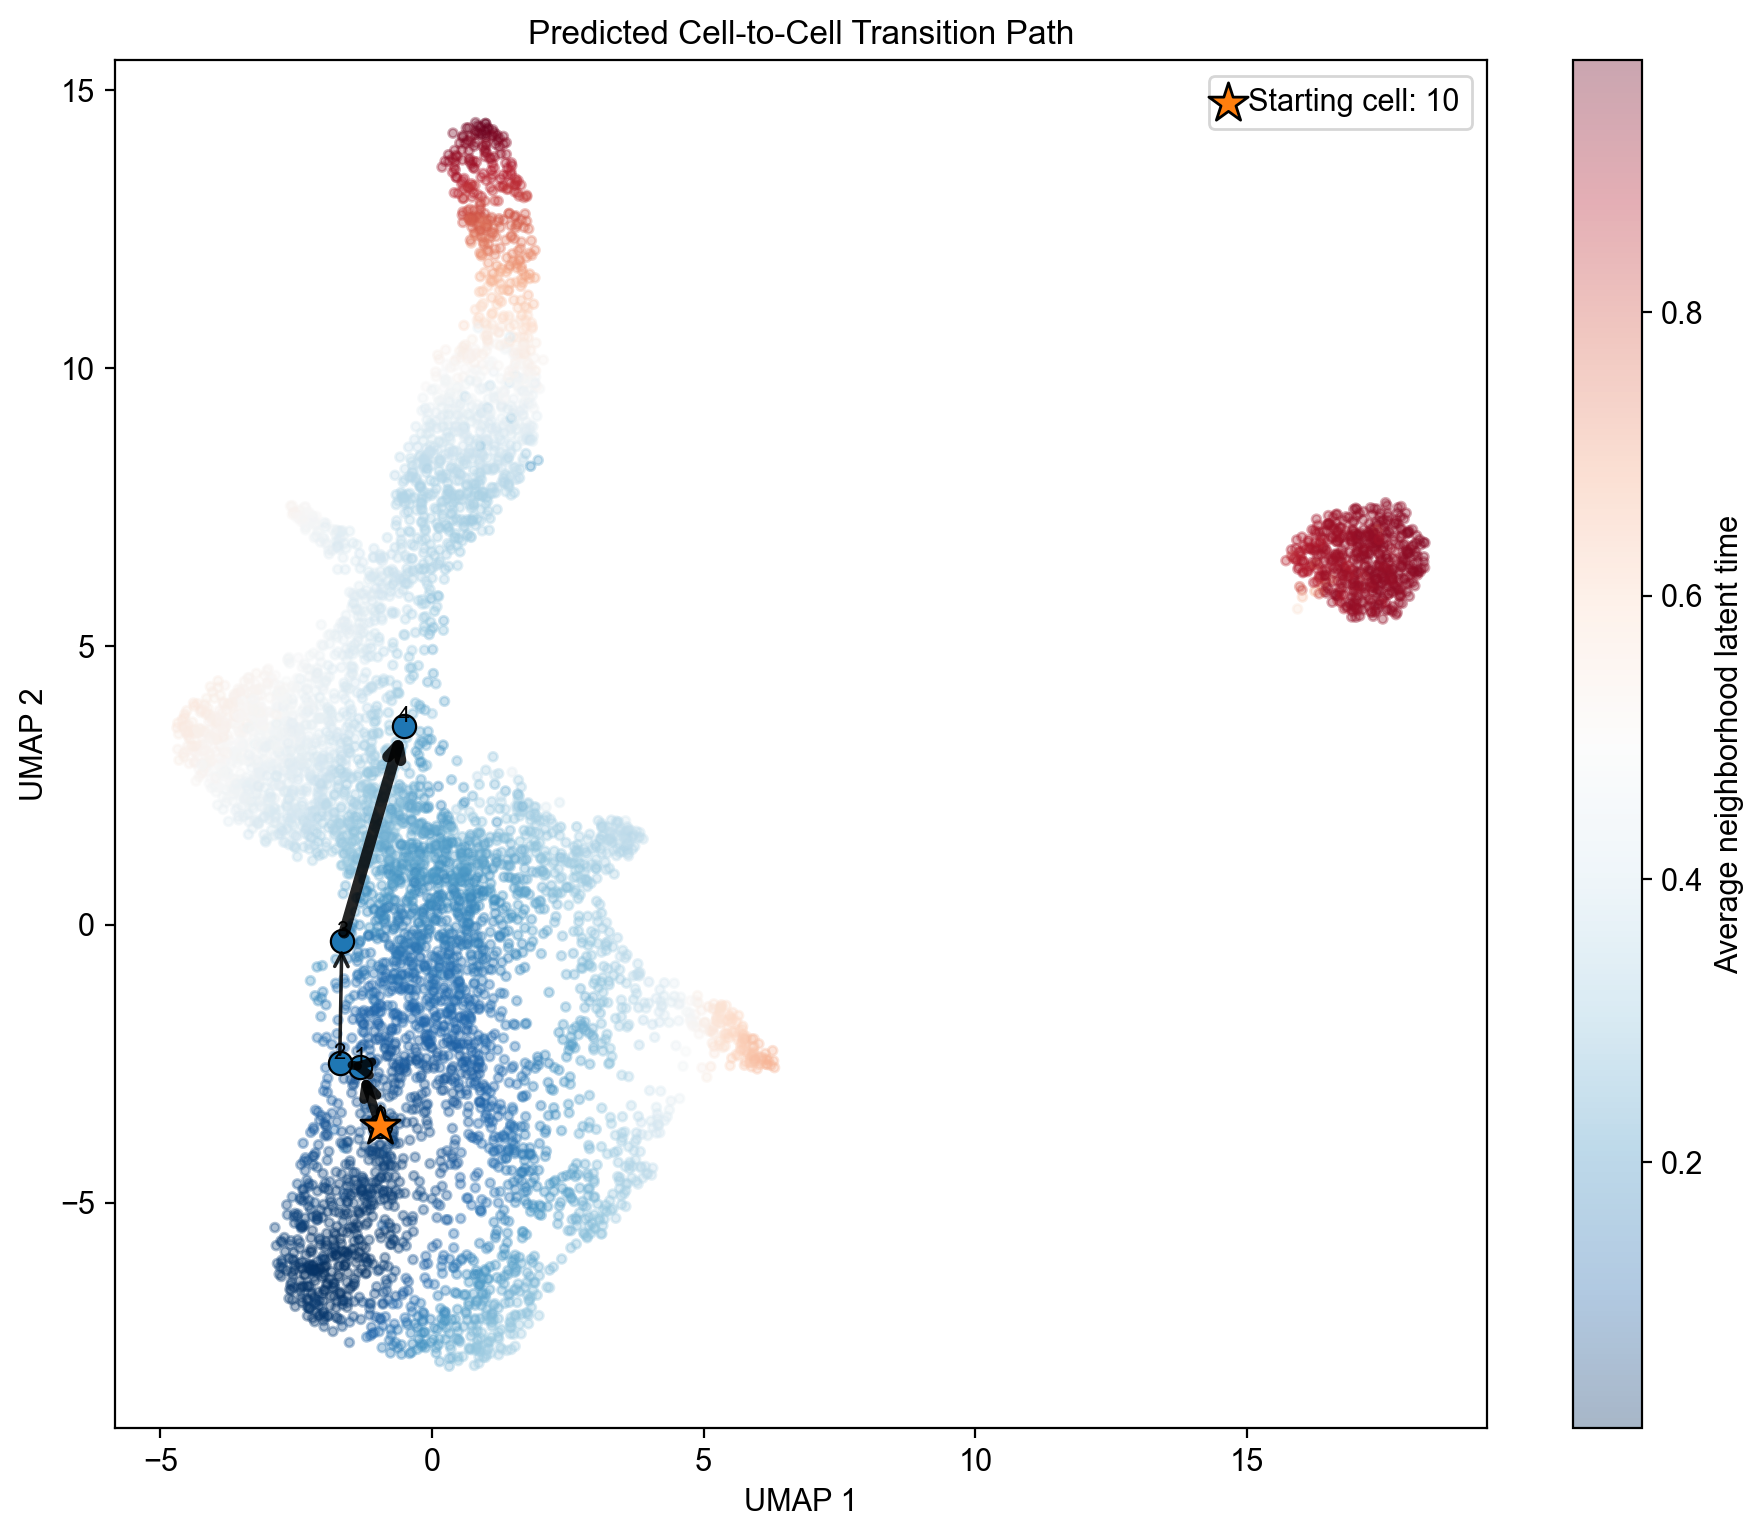

In [25]:
umap = adata.obsm["X_umap"]

plt.figure(figsize=(11, 9))

# Plot all cells in the background
background = plt.scatter(
    umap[:, 0],
    umap[:, 1],
    c=adata.obs["avg_latent_time"],
    s=10,
    alpha=0.35
)

plt.colorbar(
    background,
    label="Average neighborhood latent time"
)

# Draw the selected cells
path_coordinates = umap[cell_idx_sequence]

plt.scatter(
    path_coordinates[:, 0],
    path_coordinates[:, 1],
    s=70,
    edgecolors="black",
    linewidths=0.8,
    zorder=3
)

# Draw cell-to-cell arrows
for step, probability in enumerate(transition_sequence):

    source_idx = cell_idx_sequence[step]
    target_idx = cell_idx_sequence[step + 1]

    source_x, source_y = umap[source_idx]
    target_x, target_y = umap[target_idx]

    plt.annotate(
        "",
        xy=(target_x, target_y),
        xytext=(source_x, source_y),
        arrowprops={
            "arrowstyle": "->",
            "linewidth": 1 + probability * 4,
            "alpha": 0.85,
            "shrinkA": 3,
            "shrinkB": 3
        },
        zorder=4
    )

# Label path order
for step, cell_idx in enumerate(cell_idx_sequence):

    x, y = umap[cell_idx]

    plt.text(
        x,
        y,
        str(step),
        fontsize=8,
        ha="center",
        va="bottom",
        zorder=5
    )

# Mark the starting cell
start_idx = cell_idx_sequence[0]

plt.scatter(
    umap[start_idx, 0],
    umap[start_idx, 1],
    s=220,
    marker="*",
    edgecolors="black",
    label=f"Starting cell: {start_idx}",
    zorder=6
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Predicted Cell-to-Cell Transition Path")
plt.legend()
plt.show()

### LOOKING AT THE STRUCTURE OF THE ADATA

In [20]:
print(adata)
print(adata.layers.keys())
print(adata.obsp.keys())
print(adata.obs.columns)

AnnData object with n_obs × n_vars = 5780 × 2000
    obs: 'clusters', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'transition_prob', 'root_cells', 'end_points', 'velocity_pseudotime', 'latent_time', 'avg_latent_time'
    var: 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling'
    uns: 'clusters_colors', 'pca', 'neighbors', 'velocity_params', 'velocity_graph', 'velocity_graph_neg', 'recover_dynamics', 'umap'
    obsm: 'X_tsne', 'X_pca', 'X_umap'
    varm: 'PCs', 'loss'
    layers: 'spliced', 'unspliced', 'Ms', 'Mu', 'velocity', 'variance_velocity', 'fit_t', 'fit_tau', 'fit_tau_'
    obs

### CREATING ANOTHER VELOCITY MAP

In [10]:
scv.tl.velocity_graph(
    adata,
    vkey = "velocity"
)

computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/5780 [00:00<?, ?cells/s]

    finished (0:00:23) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [8]:
sc.pp.neighbors(  
    adata,
    n_neighbors=30, # Find the nearby cells
    n_pcs=30 # Search the first principal components
)

scv.tl.umap(adata)

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


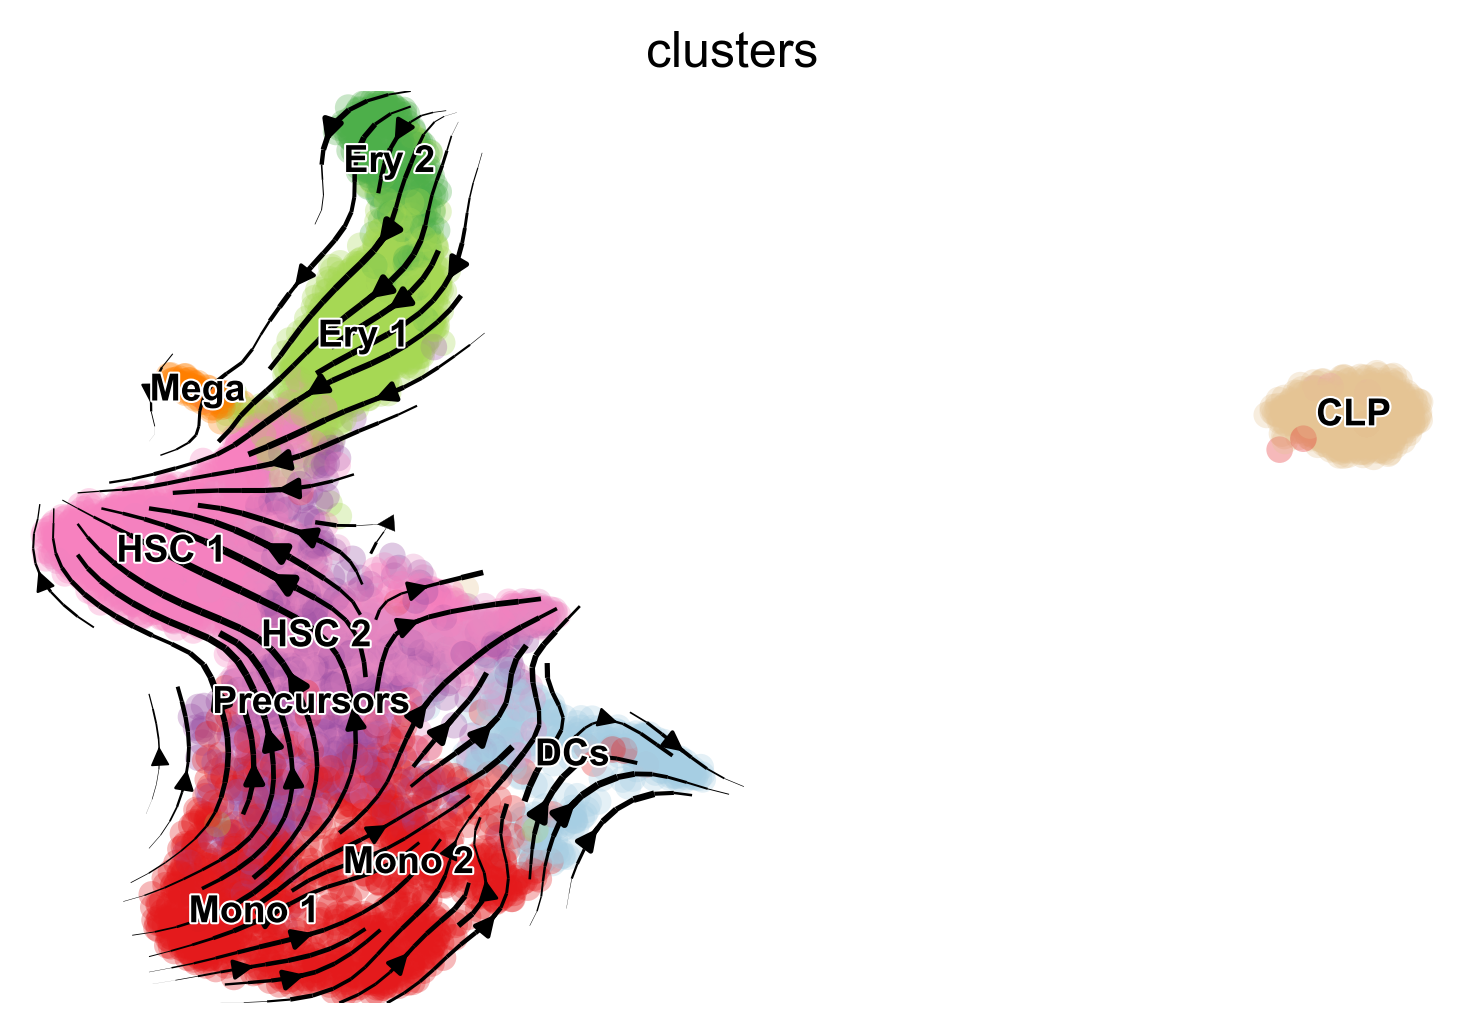

In [59]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="clusters",
    legend_fontsize=9,
    dpi=150            # increase dpi for higher resolution
)

### CREATING ANOTHER TRANSITION MATRIX

In [60]:
transition_matrix = scv.utils.get_transition_matrix(
    adata,
    vkey = "velocity"
)

print(type(transition_matrix))
print(transition_matrix.shape)

<class 'scipy.sparse._csr.csr_matrix'>
(5780, 5780)


In [61]:
rows_sums = np.asarray(
    transition_matrix.sum(axis = 1)
).flatten()

print(rows_sums[:10])
print("Minimum row sum:", rows_sums.min())
print("Maximum row sum:", rows_sums.max())
print("Average row sum:", rows_sums.mean())

[1.         1.         1.         0.9999999  0.99999994 0.9999999
 0.9999998  1.         1.0000001  0.99999994]
Minimum row sum: 0.99999976
Maximum row sum: 1.0000004
Average row sum: 1.0


In [62]:
# Save the cell level matrix

adata.obsp["deepvelo_transition_matrix"] = transition_matrix

In [63]:
# Save the ann data

adata.write_h5ad(
    "deepvelo_with_transition_matrix.h5ad"
)

### Creating a cluster-level transition matrix

In [64]:
def create_cluster_transition_matrix(
    adata,
    cell_transition_matrix,
    cluster_key = "clusters",
    normalize = True
):

    labels = adata.obs[cluster_key].astype(str).to_numpy()
    clusters = pd.Index(pd.unique(labels))

    cluster_matrix = np.zeros(
        (len(clusters), len(clusters)),
        dtype=float
    )

    for source_index, source_cluster in enumerate(clusters):
        source_cells = np.where(labels == source_cluster)[0]

        for target_index, target_cluster in enumerate(clusters):
            target_cells = np.where(labels == target_cluster)[0]

            block = cell_transition_matrix[
                source_cells, :
            ][:, target_cells]

            if sparse.issparse(block):
                transition_sum = block.sum()
            else:
                transition_sum = np.sum(block)

            cluster_matrix[
                source_index,
                target_index
            ] = float(transition_sum)

    if normalize:
        row_sums = cluster_matrix.sum(
            axis=1,
            keepdims=True
        )

        cluster_matrix = np.divide(
            cluster_matrix,
            row_sums,
            out=np.zeros_like(cluster_matrix),
            where=row_sums != 0
        )

    return pd.DataFrame(
        cluster_matrix,
        index=clusters,
        columns=clusters
    )

In [65]:
# Run the transition matrix
cluster_transition_matrix = (
    create_cluster_transition_matrix(
        adata = adata,
        cell_transition_matrix=transition_matrix,
        cluster_key="clusters",
        normalize=True
    )
)

cluster_transition_matrix

,Ery_1,HSC_1,Mono_1,Precursors,Mega,HSC_2,Mono_2,Ery_2,DCs,CLP
Ery_1,0.887689,0.048273,0.000469,0.007532,0.008886,0.015923,3.160692e-04,3.072481e-02,0.000178,0.000008
HSC_1,0.013266,0.808157,0.000098,0.023752,0.001676,0.148825,1.180884e-04,2.067377e-06,0.001995,0.002111
Mono_1,0.001849,0.001895,0.577256,0.163385,0.000907,0.056471,1.816672e-01,4.412175e-05,0.012486,0.004040
Precursors,0.016717,0.062370,0.064164,0.417552,0.000440,0.375883,4.443758e-02,1.428522e-05,0.013214,0.005208
Mega,0.171261,0.088121,0.000000,0.014731,0.703790,0.022096,0.000000e+00,0.000000e+00,0.000000,0.000000
HSC_2,0.006031,0.234531,0.005534,0.204148,0.000168,0.525642,9.261055e-03,1.614497e-05,0.008957,0.005711
Mono_2,0.000056,0.000130,0.137089,0.135412,0.000000,0.072429,5.909358e-01,0.000000e+00,0.063947,0.000000
Ery_2,0.217187,0.000035,0.000017,0.000109,0.000000,0.000305,0.000000e+00,7.823382e-01,0.000000,0.000009
DCs,0.000123,0.003600,0.008271,0.058663,0.000000,0.068417,6.022432e-02,1.808746e-06,0.800699,0.000000
CLP,0.000005,0.001781,0.001671,0.000111,0.000000,0.005611,1.105188e-07,7.846818e-07,0.000002,0.990817


In [66]:
cluster_transition_no_self = (
    cluster_transition_matrix.copy()
)

np.fill_diagonal(
    cluster_transition_no_self.values,
    0
)

row_sums = cluster_transition_no_self.sum(axis=1)

cluster_transition_no_self = (
    cluster_transition_no_self.div(
        row_sums.replace(0, np.nan),
        axis=0
    )
    .fillna(0)
)

cluster_transition_no_self

,Ery_1,HSC_1,Mono_1,Precursors,Mega,HSC_2,Mono_2,Ery_2,DCs,CLP
Ery_1,0.000000,0.429820,0.004174,0.067064,0.079121,0.141779,0.002814,0.273569,0.001587,0.000073
HSC_1,0.069148,0.000000,0.000508,0.123810,0.008737,0.775765,0.000616,0.000011,0.010401,0.011005
Mono_1,0.004373,0.004483,0.000000,0.386487,0.002145,0.133582,0.429733,0.000104,0.029536,0.009556
Precursors,0.028701,0.107083,0.110163,0.000000,0.000756,0.645351,0.076294,0.000025,0.022687,0.008941
Mega,0.578176,0.297497,0.000000,0.049732,0.000000,0.074596,0.000000,0.000000,0.000000,0.000000
HSC_2,0.012714,0.494417,0.011666,0.430368,0.000355,0.000000,0.019523,0.000034,0.018883,0.012040
Mono_2,0.000138,0.000318,0.335129,0.331028,0.000000,0.177060,0.000000,0.000000,0.156326,0.000000
Ery_2,0.997817,0.000160,0.000077,0.000502,0.000000,0.001403,0.000000,0.000000,0.000000,0.000041
DCs,0.000619,0.018062,0.041501,0.294344,0.000000,0.343286,0.302178,0.000009,0.000000,0.000000
CLP,0.000522,0.193948,0.181979,0.012141,0.000000,0.611054,0.000012,0.000085,0.000258,0.000000


### Create the heat map

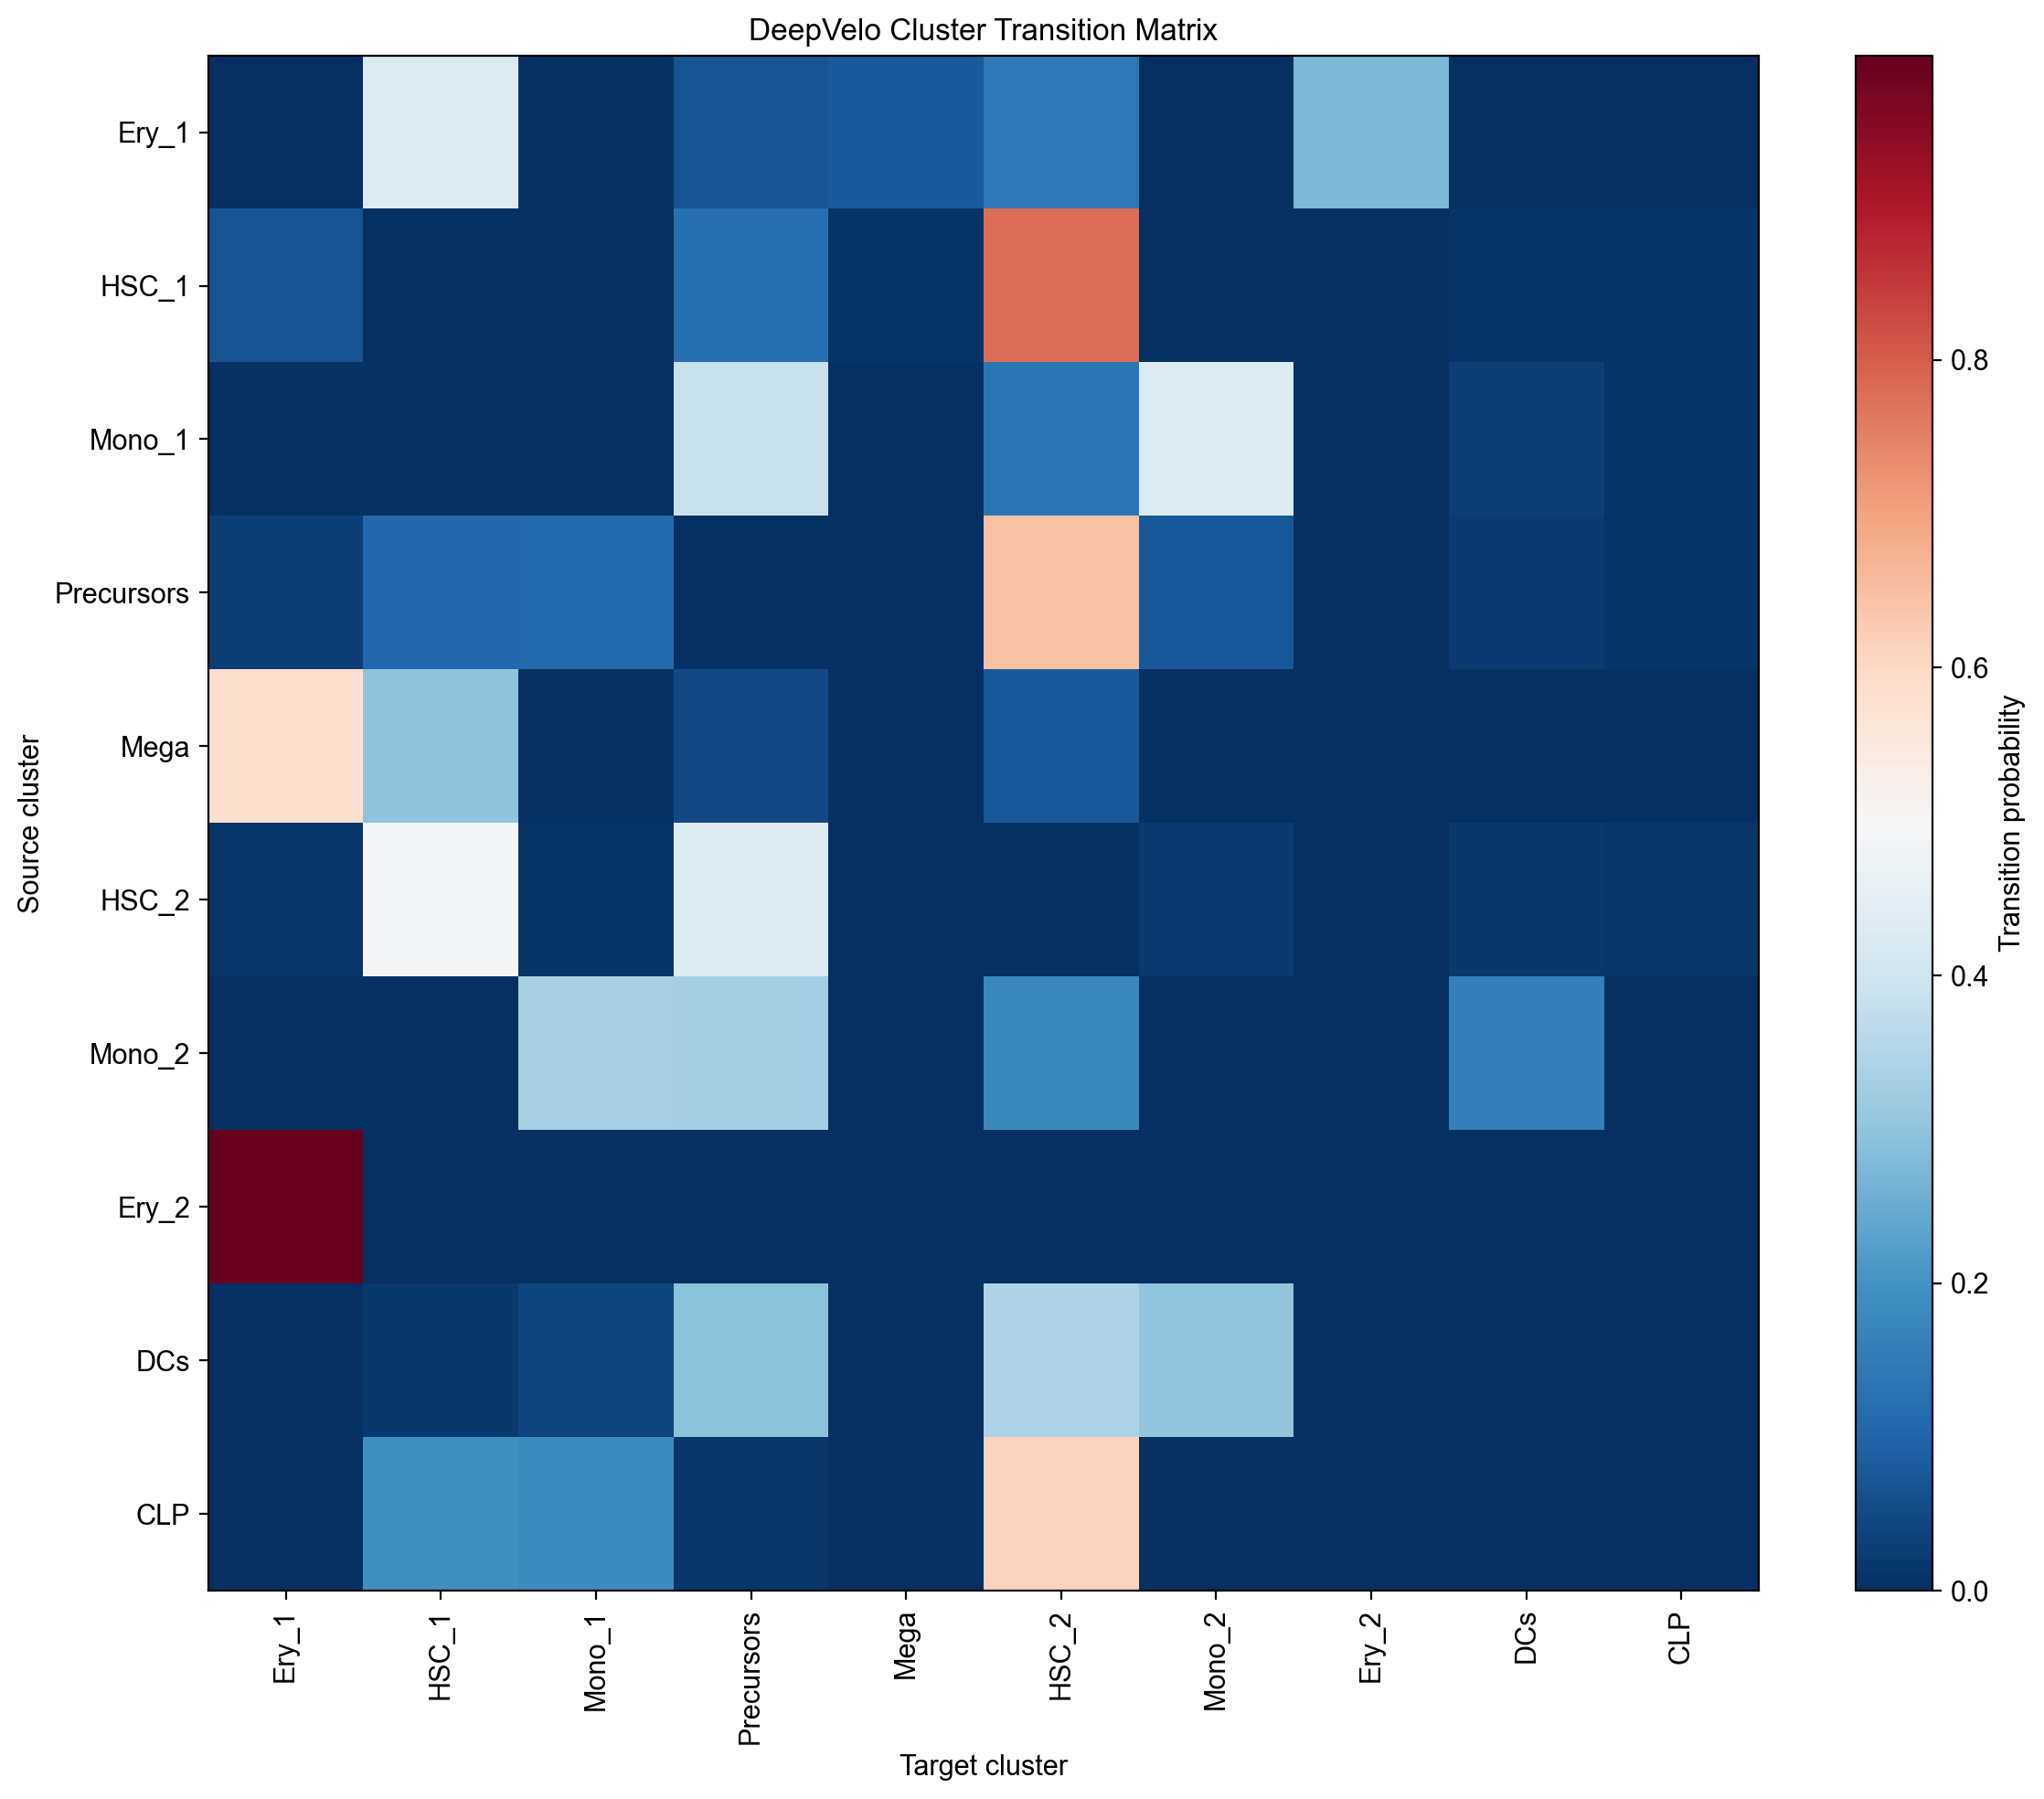

In [67]:
plt.figure(figsize=(12, 10))

plt.imshow(
    cluster_transition_no_self,
    aspect="auto"
)

plt.colorbar(
    label="Transition probability"
)

plt.xticks(
    ticks=np.arange(
        len(cluster_transition_no_self.columns)
    ),
    labels=cluster_transition_no_self.columns,
    rotation=90
)

plt.yticks(
    ticks=np.arange(
        len(cluster_transition_no_self.index)
    ),
    labels=cluster_transition_no_self.index
)

plt.xlabel("Target cluster")
plt.ylabel("Source cluster")
plt.title(
    "DeepVelo Cluster Transition Matrix"
)

plt.tight_layout()
plt.show()

In [68]:
cluster_edges = [
    ("HSC_1", "HSC_2"),
    ("HSC_2", "Precursors"),
    ("Precursors", "GMP"),
    ("Precursors", "MEP"),
    ("Precursors", "CLP"),
]

In [69]:
expected_transition_results = []

for source, target in cluster_edges:
    if (
        source in cluster_transition_no_self.index
        and target in cluster_transition_no_self.columns
    ):
        probability = cluster_transition_no_self.loc[
            source,
            target
        ]

        expected_transition_results.append(
            {
                "source_cluster": source,
                "target_cluster": target,
                "transition_probability": probability
            }
        )
    else:
        print(
            f"Missing cluster: {source} or {target}"
        )

expected_transition_df = pd.DataFrame(
    expected_transition_results
)

expected_transition_df

Missing cluster: Precursors or GMP
Missing cluster: Precursors or MEP


,source_cluster,target_cluster,transition_probability
0,HSC_1,HSC_2,0.775765
1,HSC_2,Precursors,0.430368
2,Precursors,CLP,0.008941


In [70]:
expected_transition_df.sort_values(
    "transition_probability",
    ascending=False
)

,source_cluster,target_cluster,transition_probability
0,HSC_1,HSC_2,0.775765
1,HSC_2,Precursors,0.430368
2,Precursors,CLP,0.008941


Cell-Level Transition Plot



In [71]:
coordinates = adata.obsm["X_tsne"]

expected_positions = transition_matrix.dot(coordinates)

transition_vectors = expected_positions - coordinates

print(coordinates.shape)
print(expected_positions.shape)
print(transition_vectors.shape)

(5780, 2)
(5780, 2)
(5780, 2)


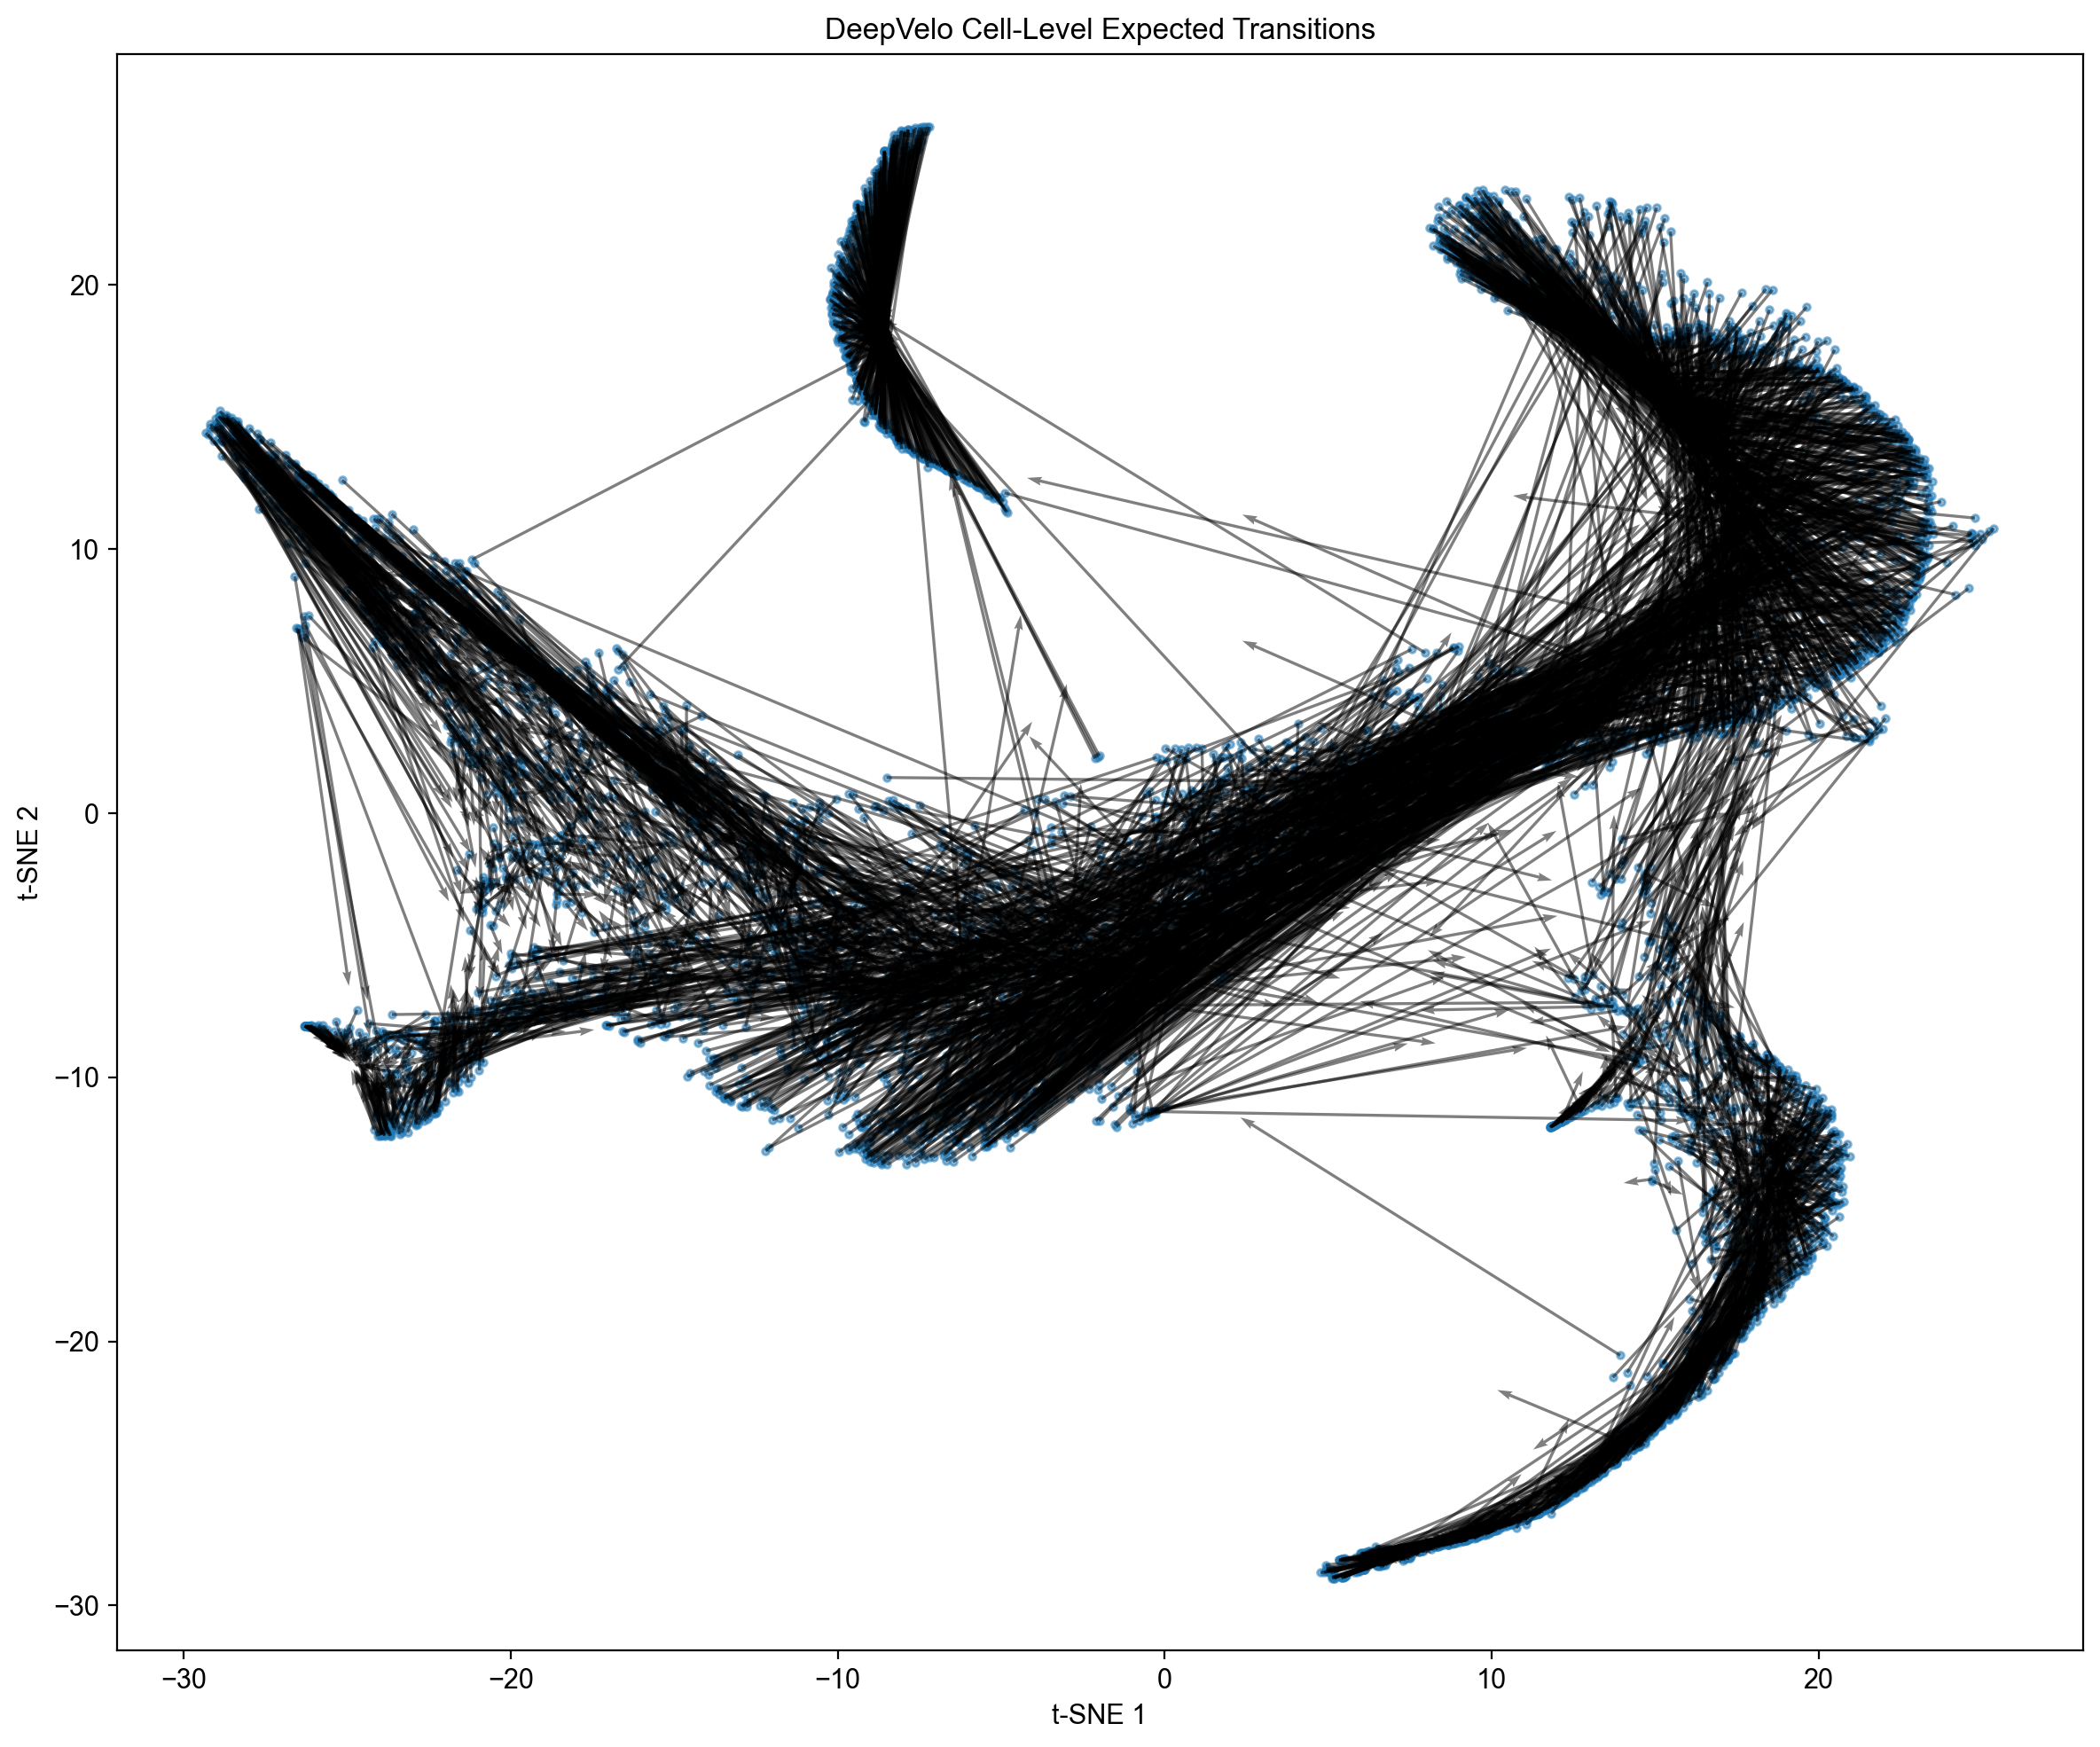

In [ ]:
# Try to create the arrows for thsi
plt.figure(figsize=(12, 10))

# Plot cells
plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    s=8,
    alpha=0.5
)

# Plot one transition arrow per cell
plt.quiver(
    coordinates[:, 0],
    coordinates[:, 1],
    transition_vectors[:, 0],
    transition_vectors[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.0015,
    alpha=0.5
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("DeepVelo Cell-Level Expected Transitions")

plt.tight_layout()
plt.show()

Looking at the cell path

In [73]:
path = scv.utils.get_cell_transitions(
    adata,
    starting_cell=0,
    basis="tsne",
    n_steps=20,
    random_state=42
)

path

array([[ 20.76806476,  20.54169475,  19.54942482,  19.47816514,
         20.34421108,  20.60120167,  20.39842141,  19.93757066,
         20.04018145,  20.6097187 ,  20.68183907,  19.94314024,
         19.55166217,  19.41179157,  19.93136362,  19.87262882,
         19.68666174],
       [-12.99363748, -12.16796333, -12.66019326, -13.58168389,
        -14.56155613, -14.17026237, -12.41949965, -11.97022772,
        -11.89573455, -13.86811574, -12.78730038, -10.73089941,
        -12.18303994, -10.63273982, -10.43724968, -11.51290296,
        -10.74039686]])

In [51]:
def most_likely_cell_path(
    transition_matrix,
    starting_cell=0,
    n_steps=20,
    prevent_revisits=True
):
    matrix = transition_matrix.tocsr()
    current_cell = starting_cell
    path = [current_cell]

    for _ in range(n_steps):
        row = matrix.getrow(current_cell).copy()

        if prevent_revisits:
            row[:, path] = 0
            row.eliminate_zeros()

        if row.nnz == 0:
            break

        next_cell = row.indices[np.argmax(row.data)]

        path.append(next_cell)
        current_cell = next_cell

    return np.array(path)

In [52]:
cell_path = most_likely_cell_path(
    transition_matrix=transition_matrix,
    starting_cell=0,
    n_steps=20
)

cell_path

array([   0, 5282, 5648, 3605, 4127, 2207, 3565, 5013, 3927, 3482, 5609,
       3324, 5369, 5122, 2372, 2986, 4167, 4404, 2987, 4224, 5020])

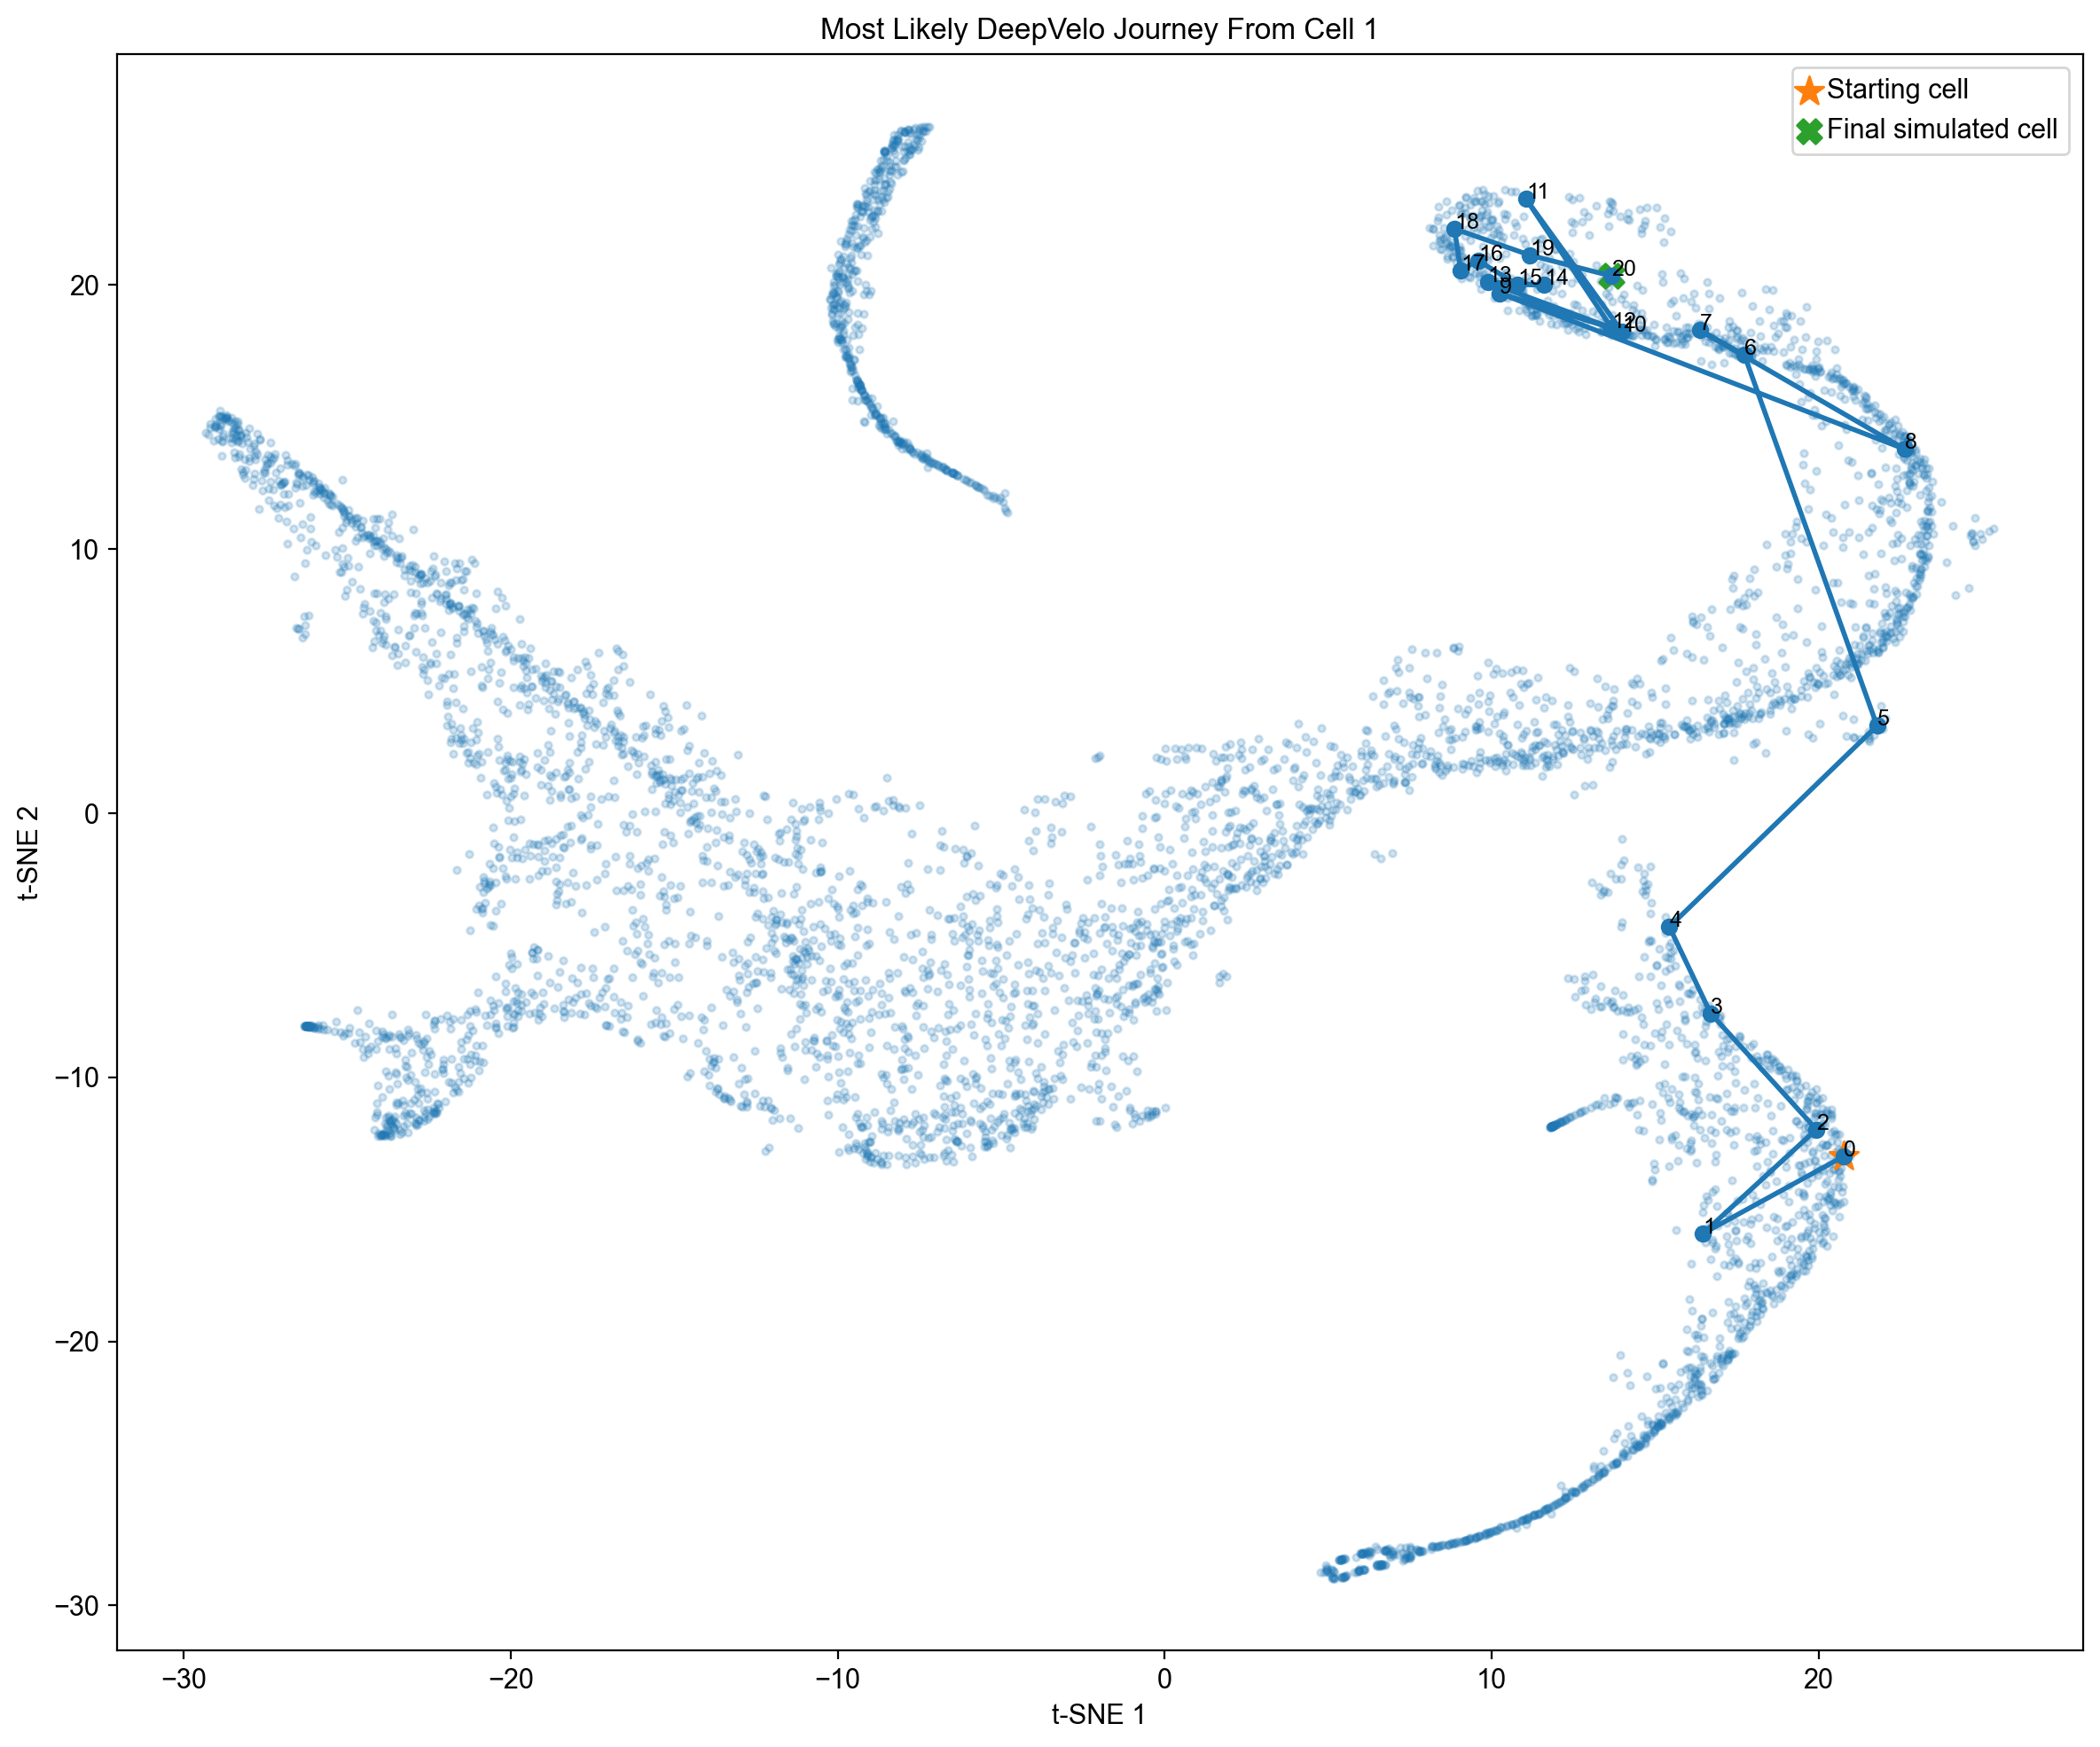

In [53]:
coordinates = adata.obsm["X_tsne"]
path_coordinates = coordinates[cell_path]

plt.figure(figsize=(12, 10))

# Background cells
plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    s=8,
    alpha=0.2
)

# Journey line
plt.plot(
    path_coordinates[:, 0],
    path_coordinates[:, 1],
    marker="o",
    linewidth=2
)

# Starting cell
plt.scatter(
    path_coordinates[0, 0],
    path_coordinates[0, 1],
    s=150,
    marker="*",
    label="Starting cell"
)

# Ending cell
plt.scatter(
    path_coordinates[-1, 0],
    path_coordinates[-1, 1],
    s=100,
    marker="X",
    label="Final simulated cell"
)

# Label each step
for step, (x, y) in enumerate(path_coordinates):
    plt.text(
        x,
        y,
        str(step),
        fontsize=9
    )

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Most Likely DeepVelo Journey From Cell 1")
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
def sample_cell_path(
    transition_matrix,
    starting_cell=0,
    n_steps=20,
    random_state=42,
    prevent_revisits=True
):
    rng = np.random.default_rng(random_state)
    matrix = transition_matrix.tocsr()

    current_cell = starting_cell
    path = [current_cell]

    for _ in range(n_steps):
        row = matrix.getrow(current_cell)

        candidate_cells = row.indices.copy()
        probabilities = row.data.copy()

        if prevent_revisits:
            keep = ~np.isin(candidate_cells, path)
            candidate_cells = candidate_cells[keep]
            probabilities = probabilities[keep]

        if len(candidate_cells) == 0:
            break

        probability_sum = probabilities.sum()

        if probability_sum <= 0:
            break

        probabilities = probabilities / probability_sum

        next_cell = rng.choice(
            candidate_cells,
            p=probabilities
        )

        path.append(next_cell)
        current_cell = next_cell

    return np.array(path)

In [55]:
sampled_path = sample_cell_path(
    transition_matrix,
    starting_cell=0,
    n_steps=20,
    random_state=42
)

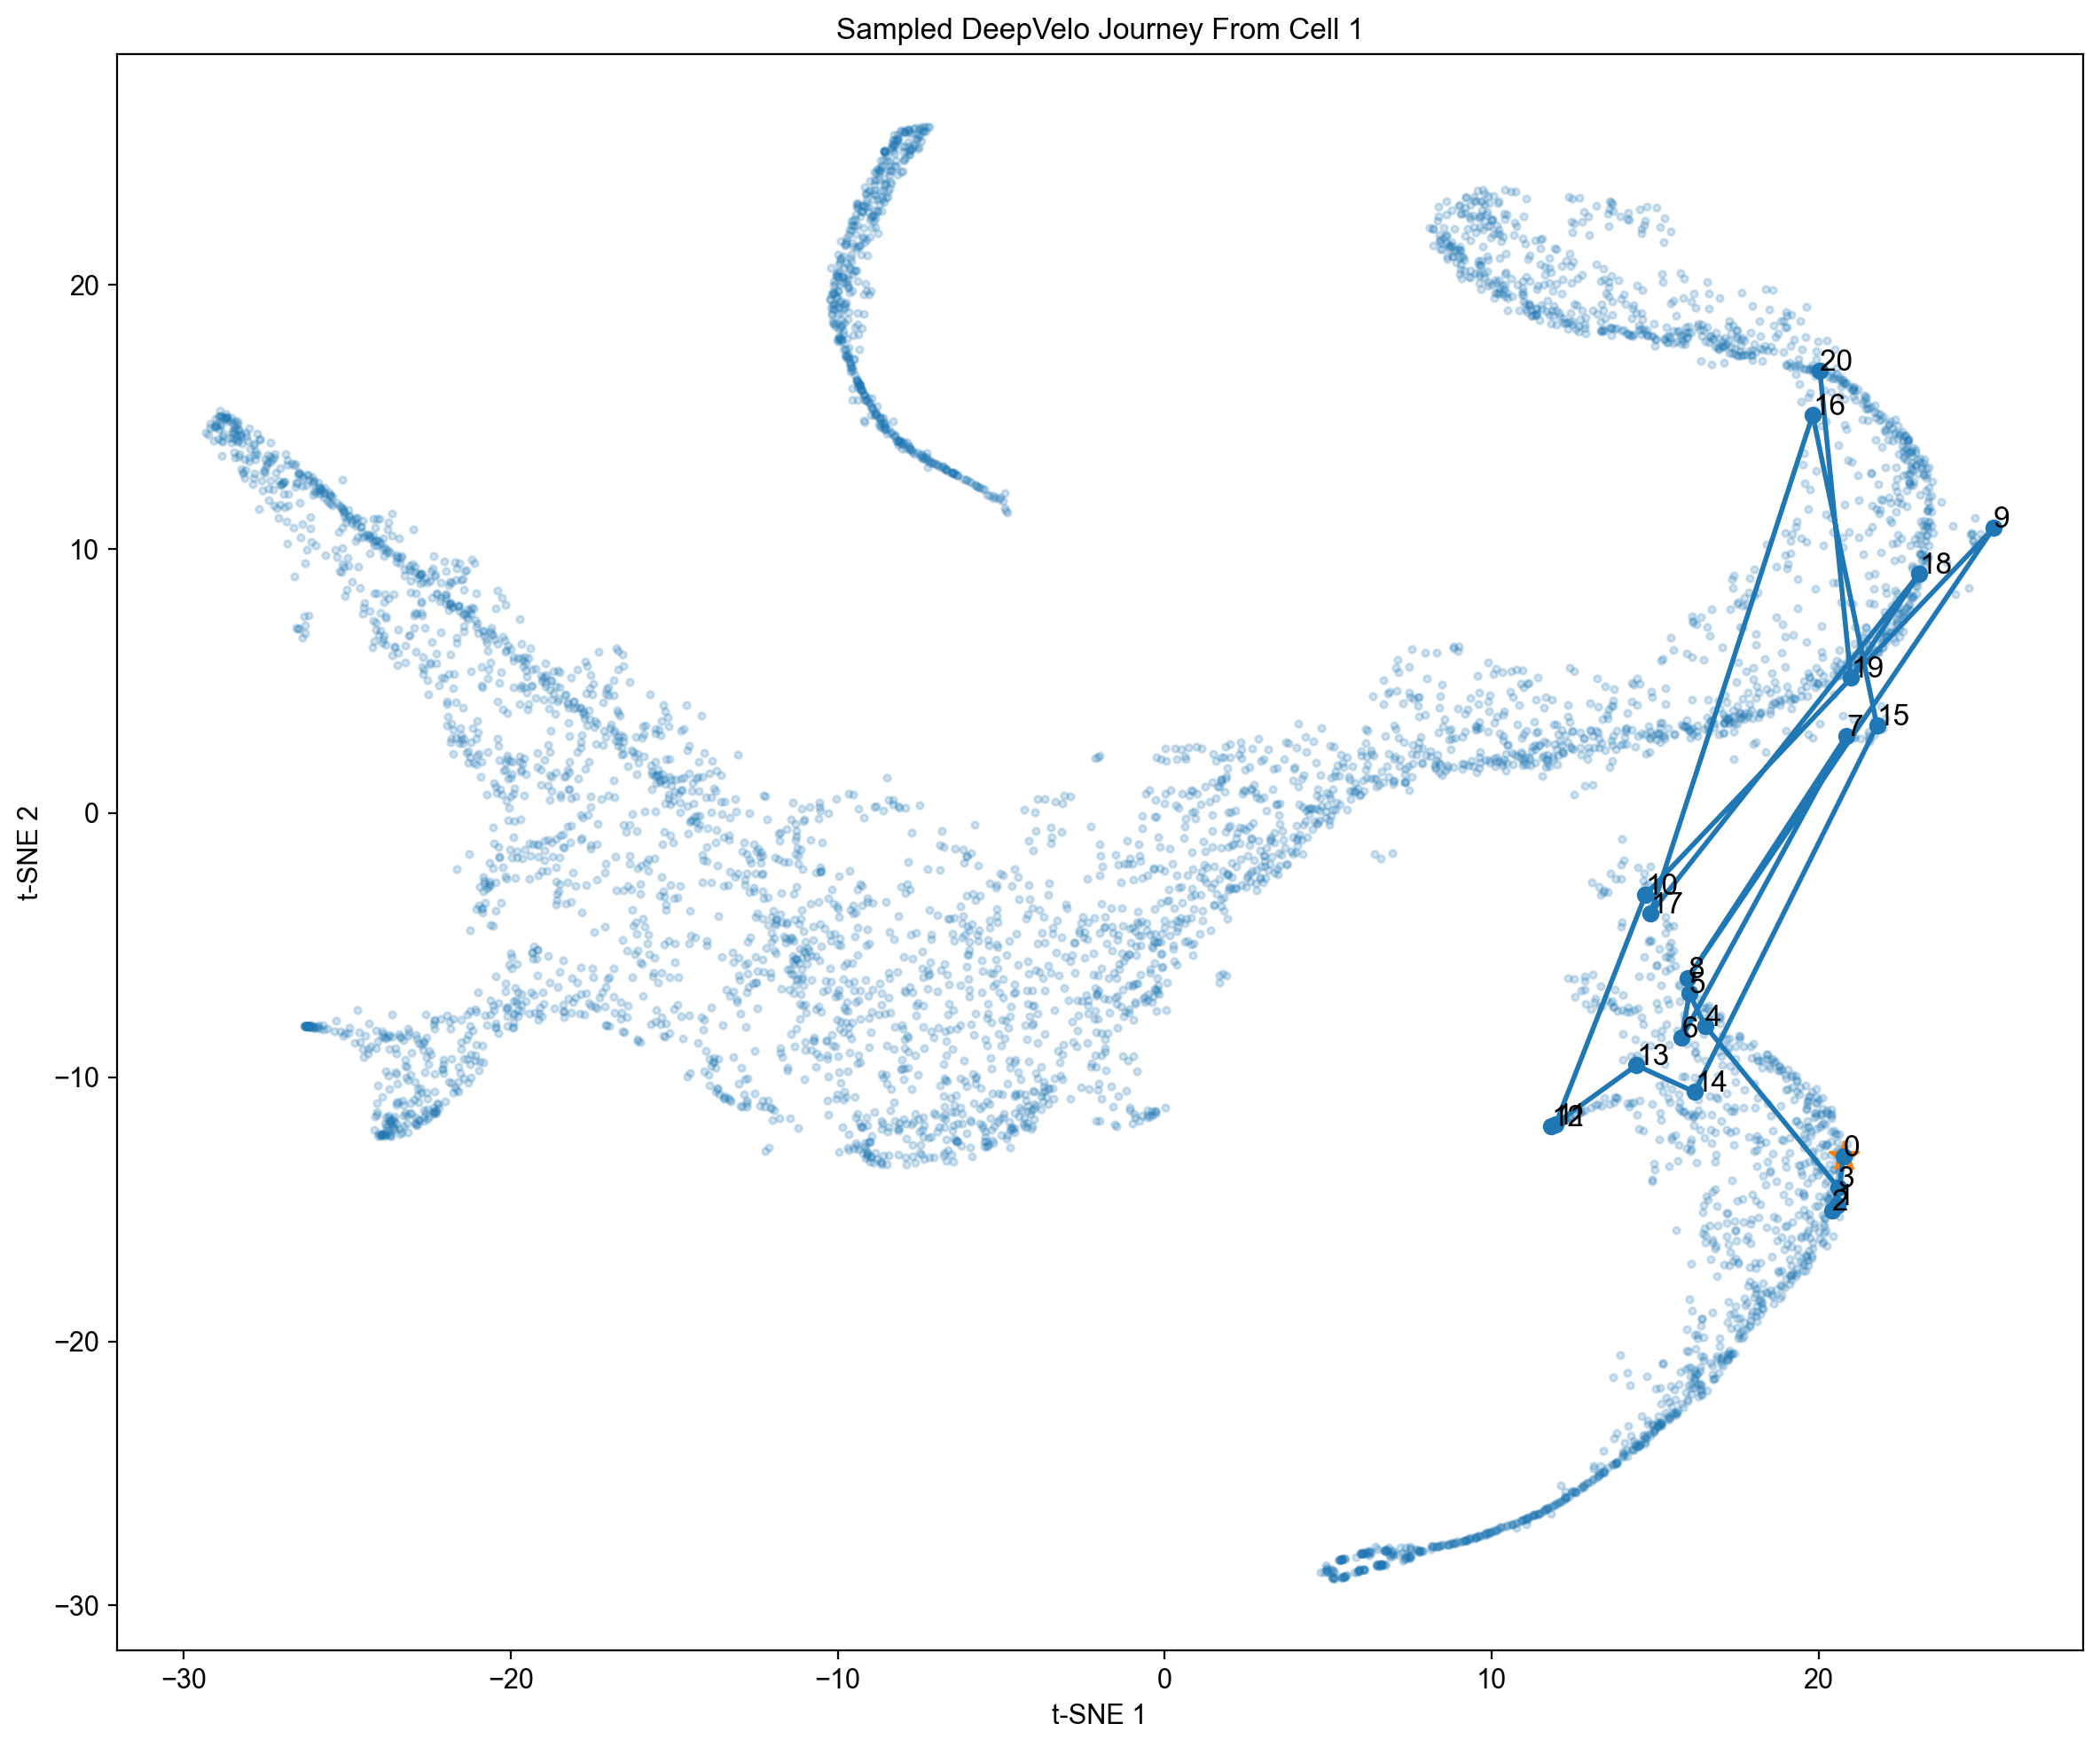

In [56]:
sampled_coordinates = coordinates[sampled_path]

plt.figure(figsize=(12, 10))

plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    s=8,
    alpha=0.2
)

plt.plot(
    sampled_coordinates[:, 0],
    sampled_coordinates[:, 1],
    marker="o",
    linewidth=2
)

plt.scatter(
    sampled_coordinates[0, 0],
    sampled_coordinates[0, 1],
    s=150,
    marker="*"
)

for step, (x, y) in enumerate(sampled_coordinates):
    plt.text(x, y, str(step))

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Sampled DeepVelo Journey From Cell 1")

plt.tight_layout()
plt.show()